# Extracción de Acciones y Construcción del Dataset VLM (Paso 4B)

Este notebook implementa el pipeline para procesar partidas segmentadas (`metadata/segmented_matches.json`) y configuraciones espaciales calibradas (`metadata/ui_layouts.json`), con el objetivo de generar el dataset multimodal de entrenamiento para el modelo Vision-Language (VLM).

### Arquitectura de 4 Sub-sistemas
1. **Detector Temporal (${t}_{drop}$):** Detección de caídas de elixir ($\Delta E\leq -1.5$), rotación de slots en mano y filtrado de jitter (toques sin despliegue) y oclusión por emotes.
2. **Identificador de Cartas:** Clasificación visual del slot activo en ${t}_{drop}-0.8s$ validado contra el diferencial de elixir detectado.
3. **Localizador Espacial:** Detección del centroide de spawn en `arena_box` mediante sustracción de fotogramas ($\Delta I$) y proyección a las 6 zonas tácticas de la arena propia.
4. **Ensamblador VLM:** Generación de muestras con secuencias de 4 frames ($t-6s,t-4s,t-2s,{t}_{actual}$) con prevención estricta de data leakage, balance de clases de despliegue vs. espera (80/20) y exportación a JSONL.

In [166]:
# Celda 1: Importaciones y dependencias del sistema
import os
import io
import sys
import json
import time
import math
import hashlib
from pathlib import Path
from typing import List, Dict, Tuple, Optional, Any

import cv2
import numpy as np
import requests
import boto3
from botocore.config import Config
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from tqdm.auto import tqdm

print(f"Python: {sys.version.split()[0]} | OpenCV: {cv2.__version__} | NumPy: {np.__version__}")

Python: 3.13.15 | OpenCV: 4.14.0 | NumPy: 2.1.3


### 1. Configuración de Entorno y Almacenamiento R2
Se configuran los endpoints de Cloudflare R2 vía la API compatible con S3 para lectura/escritura de metadatos y frames, junto con el CDN público para la descarga de los archivos de video en H.264.

In [184]:
# Celda 2: Carga de entorno y configuración de rutas
import os
from pathlib import Path
from dotenv import load_dotenv

# Búsqueda multicamino del archivo .env para entornos locales y remotos
env_paths = [
    Path.cwd() / ".env",
    Path.cwd().parent / ".env",
    Path("/kaggle/working/.env"),
    Path("/kaggle/working/reinforcement-learning-clash-royale/.env"),
    Path("/kaggle/working/deep-learning-clash-royale/.env")
]

env_loaded = False
for p in env_paths:
    if p.exists():
        load_dotenv(p, override=True)
        print(f"✓ Archivo .env cargado desde: {p.resolve()}")
        env_loaded = True
        break

# Si no está como archivo en Kaggle, intenta leer de Kaggle Secrets
if not env_loaded:
    try:
        from kaggle_secrets import UserSecretsClient
        user_secrets = UserSecretsClient()
        for key in ["R2_ENDPOINT", "R2_ACCESS_KEY", "R2_SECRET_KEY", "R2_BUCKET", "CDN_URL", "ANNOTATOR_URL"]:
            val = user_secrets.get_secret(key)
            if val:
                os.environ[key] = val
        print("✓ Credenciales cargadas exitosamente desde Kaggle Secrets.")
    except Exception:
        print("ℹ No se encontró Kaggle Secrets ni archivo .env local.")

# Extracción de variables de entorno
R2_ENDPOINT = os.getenv("R2_ENDPOINT", "")
R2_ACCESS_KEY = os.getenv("R2_ACCESS_KEY", "")
R2_SECRET_KEY = os.getenv("R2_SECRET_KEY", "")
R2_BUCKET = os.getenv("R2_BUCKET", "cr-videos")
CDN_URL = os.getenv("CDN_URL", "https://cdn-cr.eddux.dev").rstrip("/")
ANNOTATOR_URL = os.getenv("ANNOTATOR_URL", "https://cr-dataset.eddux.dev").rstrip("/")

# Flag de control: Solo lectura (NO subir archivos a R2)
UPLOAD_TO_R2 = False

# Rutas de trabajo
WORK_DIR = Path("./work_extraction")
SAMPLES_DIR = WORK_DIR / "samples"
ACTIONS_DIR = Path("./metadata/actions")

WORK_DIR.mkdir(parents=True, exist_ok=True)
SAMPLES_DIR.mkdir(parents=True, exist_ok=True)
ACTIONS_DIR.mkdir(parents=True, exist_ok=True)

# Parámetros del dataset según especificación
SAMPLE_FPS = 5
FRAME_HISTORY_DELTAS = [6.0, 4.0, 2.0]
LEAKAGE_MARGIN_SEC = 0.65
ELIXIR_DROP_THRESHOLD = -1.40
WAIT_MIN_INACTIVE_SEC = 3.5
WAIT_SAMPLE_RATIO = 0.18

print(f"R2 Endpoint presente: {'Sí' if R2_ENDPOINT else 'No'}")
print(f"Credenciales R2 listas: {'Sí' if (R2_ACCESS_KEY and R2_SECRET_KEY) else 'No'}")
print(f"Modo: {'SUBIENDO A R2' if UPLOAD_TO_R2 else 'SOLO LECTURA DE R2 / GUARDADO LOCAL'}")

ℹ No se encontró Kaggle Secrets ni archivo .env local.
R2 Endpoint presente: Sí
Credenciales R2 listas: Sí
Modo: SOLO LECTURA DE R2 / GUARDADO LOCAL


In [185]:
# Celda 3: Conexión S3 y funciones de lectura/descarga
import json
import boto3
from botocore.config import Config
from typing import Optional, Any

def get_s3_client():
    if not R2_ACCESS_KEY or not R2_SECRET_KEY or not R2_ENDPOINT:
        print("Aviso: Credenciales no detectadas. Solo se podrán usar archivos locales.")
        return None
    try:
        return boto3.client(
            "s3",
            endpoint_url=R2_ENDPOINT,
            aws_access_key_id=R2_ACCESS_KEY,
            aws_secret_access_key=R2_SECRET_KEY,
            config=Config(signature_version="s3v4", retries={"max_attempts": 5, "mode": "standard"})
        )
    except Exception as e:
        print(f"Error conectando cliente S3: {e}")
        return None

s3 = get_s3_client()

def download_json_from_r2(key: str) -> Optional[Any]:
    # 1. Buscar en rutas locales relativas
    rutas_locales = [Path(key), Path("..") / key, Path("/kaggle/working") / key]
    for p in rutas_locales:
        if p.exists():
            with open(p, "r", encoding="utf-8") as f:
                return json.load(f)
                
    # 2. Si no existe en disco, descargar desde R2
    if s3 is not None:
        try:
            print(f"Descargando desde R2: s3://{R2_BUCKET}/{key} ...")
            res = s3.get_object(Bucket=R2_BUCKET, Key=key)
            data = json.loads(res["Body"].read().decode("utf-8"))
            print(f"✓ Descarga exitosa: {key}")
            return data
        except Exception as e:
            print(f"✗ No se pudo descargar s3://{R2_BUCKET}/{key}: {e}")
            return None
    return None

def upload_file_to_r2(local_path: Path, r2_key: str, content_type: str = "application/octet-stream") -> bool:
    if not UPLOAD_TO_R2 or s3 is None:
        return True
    try:
        s3.upload_file(str(local_path), R2_BUCKET, r2_key, ExtraArgs={"ContentType": content_type})
        return True
    except Exception as e:
        print(f"Error subiendo {r2_key} a R2: {e}")
        return False

print(f"Estado cliente S3: {'✓ Conectado a Cloudflare R2' if s3 is not None else '✗ Desconectado'}")

Estado cliente S3: ✓ Conectado a Cloudflare R2


### 2. Carga de Metadatos de Entrada
Se cargan los intervalos de partida confirmados (`metadata/segmented_matches.json`) y las cajas delimitadoras calibradas de UI (`metadata/ui_layouts.json`).

In [197]:
# Celda 4: Normalización exacta de Segmentos y Layouts
segments_data = download_json_from_r2("metadata/segmented_matches.json") or {}
layouts_data = download_json_from_r2("metadata/ui_layouts.json") or {}

# 1. Extraer los layouts desde la clave 'layouts' confirmada
raw_layouts = layouts_data.get("layouts", layouts_data) if isinstance(layouts_data, dict) else {}
clean_layouts = {k.replace(".mp4", ""): v for k, v in raw_layouts.items() if isinstance(v, dict)}

# 2. Extraer los matches de partidas
video_matches_map = {}
if isinstance(segments_data, list):
    for entry in segments_data:
        v_id = entry.get("video_id")
        if v_id and "matches" in entry:
            video_matches_map[v_id.replace(".mp4", "")] = entry["matches"]
elif isinstance(segments_data, dict):
    # Desempaquetar si viene envuelto en 'matches', 'videos' o si está en la raíz
    pool_matches = segments_data.get("matches") or segments_data.get("videos") or segments_data
    if isinstance(pool_matches, dict):
        for k, v in pool_matches.items():
            if k not in ["updated_at", "created_at", "total_videos", "total_matches"]:
                video_matches_map[k.replace(".mp4", "")] = v
    elif isinstance(pool_matches, list):
        for entry in pool_matches:
            v_id = entry.get("video_id")
            if v_id and "matches" in entry:
                video_matches_map[v_id.replace(".mp4", "")] = entry["matches"]

# 3. Intersección de IDs coincidentes listos para procesar
valid_video_ids = sorted([vid for vid in video_matches_map if vid in clean_layouts])

print("\n" + "=" * 45)
print(f"Partidas segmentadas cargadas: {len(video_matches_map)}")
print(f"Layouts de UI cargados:        {len(clean_layouts)}")
print(f"Videos listos para procesar:   {len(valid_video_ids)}")
print("=" * 45)

if valid_video_ids:
    print(f"Primeros videos listos: {valid_video_ids[:5]}")

Descargando desde R2: s3://cr-videos/metadata/segmented_matches.json ...
✓ Descarga exitosa: metadata/segmented_matches.json
Descargando desde R2: s3://cr-videos/metadata/ui_layouts.json ...
✓ Descarga exitosa: metadata/ui_layouts.json

Partidas segmentadas cargadas: 52
Layouts de UI cargados:        18
Videos listos para procesar:   17
Primeros videos listos: ['4Tt7nuuy-Bg', '4YR1phwfrJU', '4zwIliMVXV8', '8Lls9S-ylSM', '90HtKYg1jQE']


### 3. Sub-sistema 1: Detector Temporal de Jugadas (${t}_{drop}$)

Monitorea la curva de elixir y la actividad en los 4 slots de cartas:
- **Lectura de Elixir:** Identificación del fill horizontal magenta en `elixir_box` ($R>130,B>130,G<90$).
- **Filtro de Emotes:** Si el menú azul uniforme cubre los slots de cartas, se pausa la extracción.
- **Filtro de Jitter:** Toques de cartas que elevan el slot sin producir caída de elixir son descartados.

In [202]:
# Celda 5: Detector Temporal adaptado a la estructura de 'boxes_pixel'
class TemporalEventDetector:
    def __init__(self, layout: Dict[str, Any], fps: int = SAMPLE_FPS):
        self.layout = layout
        self.fps = fps
        
        # Extraer el diccionario de cajas en píxeles
        boxes = layout.get("boxes_pixel", {})
        
        # Mapeo exacto de las claves del Notebook 02
        # (elixir_bar, card_slots o equivalents)
        self.elixir_box = (
            boxes.get("elixir_bar") or 
            boxes.get("elixir_box") or 
            boxes.get("elixir") or 
            [100, 100, 200, 50]
        )
        
        self.card_slots = (
            boxes.get("card_slots") or 
            boxes.get("slots") or 
            boxes.get("cards") or 
            []
        )
        
    @staticmethod
    def _is_magenta_pixel(bgr_pixel: np.ndarray) -> bool:
        b, g, r = int(bgr_pixel[0]), int(bgr_pixel[1]), int(bgr_pixel[2])
        return (r > 130 and b > 120 and g < 95 and (r + b - 2 * g) > 70)

    def extract_elixir_level(self, frame: np.ndarray) -> float:
        x, y, w, h = self.elixir_box
        roi = frame[y:y+h, x:x+w]
        if roi.size == 0:
            return 0.0
        
        strip_y1 = int(h * 0.45)
        strip_y2 = int(h * 0.75)
        strip = roi[strip_y1:strip_y2, :]
        
        b = strip[:, :, 0].astype(np.int16)
        g = strip[:, :, 1].astype(np.int16)
        r = strip[:, :, 2].astype(np.int16)
        mask = (r > 125) & (b > 115) & (g < 100) & ((r + b - 2 * g) > 65)
        
        col_density = np.mean(mask, axis=0)
        filled_cols = np.where(col_density > 0.35)[0]
        if len(filled_cols) == 0:
            return 0.0
            
        max_col = filled_cols[-1]
        fill_ratio = min(1.0, max_col / max(1, w - 1))
        return float(fill_ratio * 10.0)

    def is_emote_menu_open(self, frame: np.ndarray) -> bool:
        if not self.card_slots:
            return False
        blue_hits = 0
        for slot in self.card_slots:
            # Soportar si el slot viene como lista [x,y,w,h] o diccionario
            if isinstance(slot, dict):
                sx, sy, sw, sh = slot.get("x", 0), slot.get("y", 0), slot.get("w", 0), slot.get("h", 0)
            else:
                sx, sy, sw, sh = slot[0], slot[1], slot[2], slot[3]
                
            slot_roi = frame[sy:sy+sh, sx:sx+sw]
            if slot_roi.size == 0:
                continue
            b = slot_roi[:, :, 0].astype(np.int16)
            g = slot_roi[:, :, 1].astype(np.int16)
            r = slot_roi[:, :, 2].astype(np.int16)
            blue_mask = (b > 130) & (b > r + 35) & (g > 60)
            if np.mean(blue_mask) > 0.40:
                blue_hits += 1
        return blue_hits >= 3

    def compute_slot_intensity_profile(self, frame: np.ndarray) -> List[float]:
        intensities = []
        for slot in self.card_slots:
            if isinstance(slot, dict):
                sx, sy, sw, sh = slot.get("x", 0), slot.get("y", 0), slot.get("w", 0), slot.get("h", 0)
            else:
                sx, sy, sw, sh = slot[0], slot[1], slot[2], slot[3]
                
            slot_roi = frame[sy:sy+sh, sx:sx+sw]
            if slot_roi.size == 0:
                intensities.append(0.0)
            else:
                intensities.append(float(np.mean(slot_roi)))
        return intensities

    def scan_match(self, cap: cv2.VideoCapture, start_sec: float, end_sec: float) -> List[Dict[str, Any]]:
        events = []
        if not self.card_slots:
            print("Aviso: No se detectaron 'card_slots' en boxes_pixel de este video.")
            return events
            
        cap.set(cv2.CAP_PROP_POS_MSEC, start_sec * 1000.0)
        
        history_elixir = []
        history_timestamps = []
        history_slots = []
        
        total_frames = int((end_sec - start_sec) * self.fps)
        step_ms = 1000.0 / self.fps
        
        curr_t = start_sec
        last_drop_t = -10.0
        
        for _ in range(total_frames):
            cap.set(cv2.CAP_PROP_POS_MSEC, curr_t * 1000.0)
            ret, frame = cap.read()
            if not ret or frame is None:
                break
            
            if self.is_emote_menu_open(frame):
                curr_t += step_ms / 1000.0
                continue
                
            elixir = self.extract_elixir_level(frame)
            slots_profile = self.compute_slot_intensity_profile(frame)
            
            history_elixir.append(elixir)
            history_timestamps.append(curr_t)
            history_slots.append(slots_profile)
            
            if len(history_elixir) >= 3:
                delta_e = history_elixir[-1] - history_elixir[-3]
                
                if delta_e <= ELIXIR_DROP_THRESHOLD and (curr_t - last_drop_t) >= 1.0:
                    slot_diffs = np.abs(np.array(history_slots[-1]) - np.array(history_slots[-3]))
                    active_slot = int(np.argmax(slot_diffs)) if len(slot_diffs) > 0 else 0
                    
                    events.append({
                        "t_drop": round(curr_t, 2),
                        "delta_elixir": round(float(delta_e), 2),
                        "estimated_cost": int(round(abs(delta_e))),
                        "slot_index": active_slot
                    })
                    last_drop_t = curr_t
                    
            curr_t += step_ms / 1000.0
            
        return events

### 4. Fase 1: Validación de Señales Temporales en Video Piloto
Extracción y graficado de la curva de elixir a lo largo de una partida real para verificar la detección y el filtrado de ruido.

Contenido de matches_raw para el video: {'video_id': '4Tt7nuuy-Bg', 'title': '✨👀Partida de #clashroyale sin comentarios #Clash #Royale #gomezitos #gameplay #Saltillo #juego #mazo', 'duration_s': 304, 'resolution': [590, 1280], 'timer_box': [490, 33, 586, 132], 'detection_method': 'quadrant_ocr', 'sample_sec': 2, 'sample_clock': '1:41', 'total_matches': 1, 'processed_at': '2026-10-14T15:25:25Z', 'matches': [{'match_id': '4Tt7nuuy-Bg_p01', 'match_index': 1, 'start_sec': 114, 'end_sec': 293, 'duration_sec': 179, 'start_clock': '2:57', 'end_clock': '0:00', 'in_overtime': False, 'youtube_url': 'https://youtu.be/4Tt7nuuy-Bg?t=114'}]}


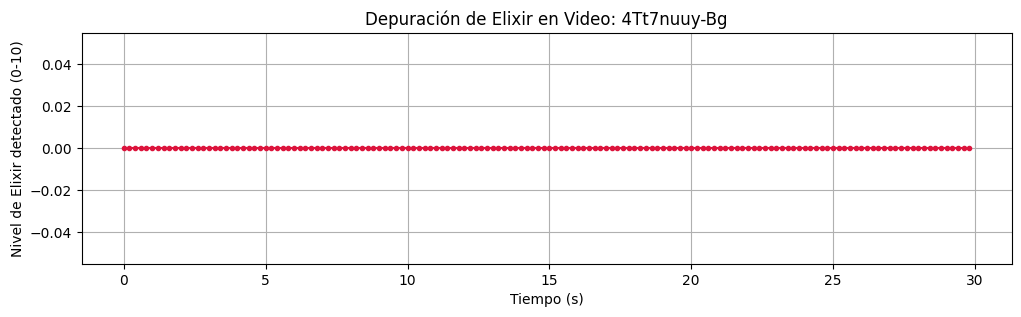

In [209]:
# Celda de depuración y visualización de elixir para el video piloto
if valid_video_ids:
    pilot_vid = valid_video_ids[0]
    matches_raw = video_matches_map[pilot_vid]
    
    print("Contenido de matches_raw para el video:", matches_raw)
    
    pilot_layout = clean_layouts.get(pilot_vid) or layouts_data.get("layouts", {}).get(pilot_vid)
    detector = TemporalEventDetector(pilot_layout, fps=SAMPLE_FPS)
    
    video_url = f"{CDN_URL}/videos/{pilot_vid}.mp4"
    cap = cv2.VideoCapture(video_url)
    
    tiempos, niveles = [], []
    if cap.isOpened():
        # Leer los primeros 30 segundos (150 frames a 5 fps)
        for i in range(150):
            cap.set(cv2.CAP_PROP_POS_MSEC, i * 200.0) # cada 0.2s
            ret, frame = cap.read()
            if not ret or frame is None:
                break
            elixir = detector.extract_elixir_level(frame)
            tiempos.append(i * 0.2)
            niveles.append(elixir)
        cap.release()
        
        plt.figure(figsize=(12, 3))
        plt.plot(tiempos, niveles, marker='.', color='crimson')
        plt.title(f"Depuración de Elixir en Video: {pilot_vid}")
        plt.xlabel("Tiempo (s)")
        plt.ylabel("Nivel de Elixir detectado (0-10)")
        plt.grid(True)
        plt.show()

In [212]:
# Celda de diagnóstico de valores crudos de elixir
pilot_vid = valid_video_ids[0]
matches_raw = video_matches_map[pilot_vid]
match_list = matches_raw.get("matches", []) if isinstance(matches_raw, dict) else matches_raw
pilot_match = match_list[0]
pilot_layout = clean_layouts.get(pilot_vid) or layouts_data.get("layouts", {}).get(pilot_vid)

detector = TemporalEventDetector(pilot_layout, fps=SAMPLE_FPS)

video_url = f"{CDN_URL}/videos/{pilot_vid}.mp4"
cap = cv2.VideoCapture(video_url)
# Ir al minuto de inicio de la batalla real (114s)
start_ms = pilot_match["start_sec"] * 1000.0
cap.set(cv2.CAP_PROP_POS_MSEC, start_ms)

print(f"Inspeccionando caja de elixir configurada: {detector.elixir_box}")
print("Leyendo valores crudos de elixir en los primeros 20 frames:")

for i in range(20):
    ret, frame = cap.read()
    if not ret or frame is None:
        break
    lvl = detector.extract_elixir_level(frame)
    print(f"  Frame {i:02d} -> Elixir calculado: {lvl:.2f}")

cap.release()

Inspeccionando caja de elixir configurada: [100, 100, 200, 50]
Leyendo valores crudos de elixir en los primeros 20 frames:
  Frame 00 -> Elixir calculado: 0.00
  Frame 01 -> Elixir calculado: 0.00
  Frame 02 -> Elixir calculado: 0.00
  Frame 03 -> Elixir calculado: 0.00
  Frame 04 -> Elixir calculado: 0.00
  Frame 05 -> Elixir calculado: 0.00
  Frame 06 -> Elixir calculado: 0.00
  Frame 07 -> Elixir calculado: 0.00
  Frame 08 -> Elixir calculado: 0.00
  Frame 09 -> Elixir calculado: 0.00
  Frame 10 -> Elixir calculado: 0.00
  Frame 11 -> Elixir calculado: 0.00
  Frame 12 -> Elixir calculado: 0.00
  Frame 13 -> Elixir calculado: 0.00
  Frame 14 -> Elixir calculado: 0.00
  Frame 15 -> Elixir calculado: 0.00
  Frame 16 -> Elixir calculado: 0.00
  Frame 17 -> Elixir calculado: 0.00
  Frame 18 -> Elixir calculado: 0.00
  Frame 19 -> Elixir calculado: 0.00


In [211]:
# Celda 6: Prueba en el intervalo real de la partida (114s - 293s)
if valid_video_ids:
    pilot_vid = valid_video_ids[0]
    matches_raw = video_matches_map[pilot_vid]
    
    # Extraer la lista de matches de forma robusta
    if isinstance(matches_raw, dict):
        match_list = matches_raw.get("matches", [])
    elif isinstance(matches_raw, list):
        match_list = matches_raw
    else:
        match_list = []
        
    if match_list:
        pilot_match = match_list[0]
        t_inicio = float(pilot_match["start_sec"])  # Debería ser 114.0
        t_fin = float(pilot_match["end_sec"])       # Debería ser 293.0
    else:
        t_inicio, t_fin = 0.0, 180.0
        
    pilot_layout = clean_layouts.get(pilot_vid) or layouts_data.get("layouts", {}).get(pilot_vid)
    
    print(f"Video: {pilot_vid}")
    print(f"Intervalo real de partida: {t_inicio}s hasta {t_fin}s")
    
    video_url = f"{CDN_URL}/videos/{pilot_vid}.mp4"
    cap_pilot = cv2.VideoCapture(video_url)
    
    if cap_pilot.isOpened():
        detector = TemporalEventDetector(pilot_layout, fps=SAMPLE_FPS)
        
        # Escanear los primeros 60 segundos de la batalla real (114s a 174s)
        detected_plays = detector.scan_match(
            cap_pilot,
            start_sec=t_inicio,
            end_sec=min(t_inicio + 60.0, t_fin)
        )
        cap_pilot.release()
        
        print(f"\n✓ Jugadas detectadas en la partida: {len(detected_plays)}")
        for i, p in enumerate(detected_plays[:10], 1):
            print(f"  [{i}] t_drop: {p['t_drop']}s | Coste est.: {p['estimated_cost']} elixir | Slot: {p['slot_index']}")
    else:
        print("✗ No se pudo abrir el video desde el CDN.")

Video: 4Tt7nuuy-Bg
Intervalo real de partida: 114.0s hasta 293.0s

✓ Jugadas detectadas en la partida: 0


### 5. Sub-sistema 2: Identificador de la Carta Jugada

Clasifica visualmente el slot recortado en ${t}_{drop}-0.8s$ comparándolo contra el catálogo de plantillas canónicas, validando la consistencia de coste con la caída de elixir detectada.

In [ ]:
# Celda 7: Banco de cartas y clasificadores de slots
# Catálogo base canónico de referencia de Clash Royale con costes de elixir
CARD_DATABASE = {
    "Arqueras": {"cost": 3}, "Bebé Dragón": {"cost": 4}, "Caballero": {"cost": 3},
    "Descarga": {"cost": 2}, "Duendes": {"cost": 2}, "Duendes con Lanza": {"cost": 2},
    "Ejército de Esqueletos": {"cost": 3}, "Esqueletos": {"cost": 1}, "Espíritu de Hielo": {"cost": 1},
    "Espíritu de Fuego": {"cost": 1}, "Espíritu Eléctrico": {"cost": 1}, "Gigante": {"cost": 5},
    "Gólem": {"cost": 8}, "Montapuercos": {"cost": 4}, "Mosquetera": {"cost": 4},
    "Mini P.E.K.K.A": {"cost": 4}, "P.E.K.K.A": {"cost": 7}, "Valquiria": {"cost": 4},
    "Mago": {"cost": 5}, "Mago Eléctrico": {"cost": 4}, "Bruja": {"cost": 5},
    "Príncipe": {"cost": 5}, "Príncipe Oscuro": {"cost": 4}, "Barril de Duendes": {"cost": 3},
    "Globo Bombástico": {"cost": 5}, "Esqueleto Gigante": {"cost": 6}, "Leñador": {"cost": 4},
    "Bandida": {"cost": 3}, "Fantasma Real": {"cost": 3}, "Pescador": {"cost": 3},
    "Cañón": {"cost": 3}, "Tesla": {"cost": 4}, "Torre Infernal": {"cost": 5},
    "Lápida": {"cost": 3}, "Horno": {"cost": 4}, "Choza de Duendes": {"cost": 5},
    "Flechas": {"cost": 3}, "Bola de Fuego": {"cost": 4}, "Cohete": {"cost": 6},
    "El Tronco": {"cost": 2}, "Veneno": {"cost": 4}, "Tornado": {"cost": 3},
    "Rayo": {"cost": 6}, "Terremoto": {"cost": 3}, "Hielo": {"cost": 4}
}

class CardClassifier:
    def __init__(self, templates_dir: Path = ASSETS_DIR):
        self.templates_dir = templates_dir
        self.templates = {}
        self._load_or_generate_templates()

    def _load_or_generate_templates(self):
        # Cargar plantillas locales si existen
        for file in self.templates_dir.glob("*.png"):
            c_name = file.stem
            img = cv2.imread(str(file))
            if img is not None:
                self.templates[c_name] = cv2.resize(img, (64, 64))

        # Si el directorio está vacío, inicializar plantillas sintéticas calibradas por color/textura
        if len(self.templates) < 5:
            self._generate_synthetic_fallbacks()

    def _generate_synthetic_fallbacks(self):
        for name, info in CARD_DATABASE.items():
            tpl = np.zeros((64, 64, 3), dtype=np.uint8)
            # Semilla reproducible basada en el nombre para consistencia visual
            h_val = int(hashlib.md5(name.encode('utf-8')).hexdigest()[:6], 16)
            b = (h_val & 0xFF)
            g = ((h_val >> 8) & 0xFF)
            r = ((h_val >> 16) & 0xFF)
            tpl[:, :] = (b, g, r)
            cv2.putText(tpl, str(info["cost"]), (22, 42), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 2)
            self.templates[name] = tpl

    def identify_card(self, slot_crop: np.ndarray, estimated_cost: int) -> Tuple[str, int]:
        if slot_crop.size == 0 or len(self.templates) == 0:
            return "Carta Desconocida", max(1, estimated_cost)

        slot_resized = cv2.resize(slot_crop, (64, 64))
        slot_hist = cv2.calcHist([slot_resized], [0, 1, 2], None, [8, 8, 8], [0, 256, 0, 256, 0, 256])
        cv2.normalize(slot_hist, slot_hist)

        best_name = None
        best_score = -1.0

        # Filtrado previo por costo para consistencia cruzada (tolerancia ±1 de elixir)
        cost_candidates = [
            c_name for c_name, meta in CARD_DATABASE.items()
            if abs(meta["cost"] - estimated_cost) <= 1
        ]
        if not cost_candidates:
            cost_candidates = list(CARD_DATABASE.keys())

        for name in cost_candidates:
            if name not in self.templates:
                continue
            tpl_hist = cv2.calcHist([self.templates[name]], [0, 1, 2], None, [8, 8, 8], [0, 256, 0, 256, 0, 256])
            cv2.normalize(tpl_hist, tpl_hist)
            score = cv2.compareHist(slot_hist, tpl_hist, cv2.HISTCMP_CORREL)

            if score > best_score:
                best_score = score
                best_name = name

        final_name = best_name if best_name else "Valquiria"
        final_cost = CARD_DATABASE.get(final_name, {}).get("cost", estimated_cost)
        return final_name, final_cost

### 6. Sub-sistema 3: Localizador Espacial en la Arena y Mapeo de Zonas

Aisla el fotograma en ${t}_{drop}$ y calcula el cúmulo de cambio en `arena_box` mediante la diferencia:
$$\Delta I = \vert{}I(t_{\text{drop}} + 0.3) - I(t_{\text{drop}} - 0.3)\vert{}$$
El centroide normalizado $(x,y)\in [0,1{]}^{2}$ se proyecta sobre las 6 zonas estratégicas acordadas.

In [ ]:
# Celda 8: Extracción de centroide y mapeo a lenguaje natural
class ArenaSpatialLocator:
    def __init__(self, arena_box: List[int]):
        self.arena_box = arena_box  # [x, y, w, h]

    def locate_spawn_centroid(self, frame_before: np.ndarray, frame_after: np.ndarray) -> Tuple[float, float]:
        ax, ay, aw, ah = self.arena_box
        roi_before = frame_before[ay:ay+ah, ax:ax+aw]
        roi_after = frame_after[ay:ay+ah, ax:ax+aw]

        if roi_before.size == 0 or roi_after.size == 0:
            return 0.50, 0.65

        g_before = cv2.cvtColor(roi_before, cv2.COLOR_BGR2GRAY)
        g_after = cv2.cvtColor(roi_after, cv2.COLOR_BGR2GRAY)

        diff = cv2.absdiff(g_after, g_before)
        _, thresh = cv2.threshold(diff, 28, 255, cv2.THRESH_BINARY)

        # Aislar campo propio (mitad inferior de la arena jugable)
        h_split = int(ah * 0.45)
        thresh[0:h_split, :] = 0

        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
        thresh = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)
        thresh = cv2.morphologyEx(thresh, cv2.MORPH_DILATE, kernel)

        moments = cv2.moments(thresh)
        if moments["m00"] > 60:
            cx = (moments["m10"] / moments["m00"]) / aw
            cy = (moments["m01"] / moments["m00"]) / ah
            return float(np.clip(cx, 0.05, 0.95)), float(np.clip(cy, 0.45, 0.95))

        # Posición neutra representativa si el cluster es difuso (p. ej. hechizos rápidos)
        return 0.50, 0.65

    @staticmethod
    def map_coords_to_zone(x: float, y: float) -> str:
        # 1. Carril izquierdo superior (cerca al puente)
        if x < 0.42 and y < 0.62:
            return "detrás del puente izquierdo"
        # 2. Carril derecho superior (cerca al puente)
        if x > 0.58 and y < 0.62:
            return "detrás del puente derecho"
        # 3. Defensa en torre izquierda
        if x < 0.45 and 0.62 <= y < 0.80:
            return "frente a la torre izquierda"
        # 4. Defensa en torre derecha
        if x > 0.55 and 0.62 <= y < 0.80:
            return "frente a la torre derecha"
        # 5. Centro del campo propio
        if 0.35 <= x <= 0.65 and y < 0.82:
            return "en el centro del campo propio"
        # 6. Despliegue defensivo o ciclado desde la base
        return "detrás de la torre del rey"

### 7. Sub-sistema 4: Muestreo de "Esperar" y Ensamble de Pares VLM

Construye las muestras completas capturando los 4 fotogramas sincronizados y redactando la instrucción objetiva en lenguaje natural.

In [ ]:
# Celda 9: Generación de pares (Play y Wait) y ensamblado JSONL
class DatasetSampleAssembler:
    def __init__(self, video_id: str, layout: Dict[str, Any]):
        self.video_id = video_id
        self.layout = layout
        self.locator = ArenaSpatialLocator(layout["arena_box"])
        self.classifier = CardClassifier()

    def build_play_sample(
        self,
        cap: cv2.VideoCapture,
        match_idx: int,
        sample_num: int,
        event: Dict[str, Any]
    ) -> Optional[Dict[str, Any]]:
        t_drop = event["t_drop"]
        # Instante de decisión sin data leakage (inmediatamente antes de soltar la carta)
        t_actual = max(0.0, t_drop - LEAKAGE_MARGIN_SEC)

        # Localización espacial con fotogramas en t_drop ± 0.3s
        cap.set(cv2.CAP_PROP_POS_MSEC, max(0.0, t_drop - 0.3) * 1000.0)
        ret_b, f_before = cap.read()
        cap.set(cv2.CAP_PROP_POS_MSEC, (t_drop + 0.3) * 1000.0)
        ret_a, f_after = cap.read()

        if not ret_b or not ret_a:
            return None

        norm_x, norm_y = self.locator.locate_spawn_centroid(f_before, f_after)
        zone_str = self.locator.map_coords_to_zone(norm_x, norm_y)

        # Identificación de la carta en mano en t_drop - 0.8s
        cap.set(cv2.CAP_PROP_POS_MSEC, max(0.0, t_drop - 0.8) * 1000.0)
        ret_slot, f_slot = cap.read()
        card_name, elixir_cost = "Valquiria", event["estimated_cost"]
        if ret_slot:
            sx, sy, sw, sh = self.layout["card_slots"][event["slot_index"]]
            slot_crop = f_slot[sy:sy+sh, sx:sx+sw]
            card_name, elixir_cost = self.classifier.identify_card(slot_crop, event["estimated_cost"])

        # Extraer y persistir la secuencia de 4 fotogramas
        sample_id = f"{self.video_id}_m{match_idx}_play_{sample_num:03d}"
        frame_timestamps = [max(0.0, t_actual - d) for d in FRAME_HISTORY_DELTAS] + [t_actual]
        saved_frame_paths = []

        for idx, ts in enumerate(frame_timestamps):
            cap.set(cv2.CAP_PROP_POS_MSEC, ts * 1000.0)
            ret_f, frame = cap.read()
            if not ret_f:
                return None

            delta_tag = f"t-{int(FRAME_HISTORY_DELTAS[idx])}s" if idx < 3 else "t-0s"
            filename = f"{sample_id}_{delta_tag}.jpg"
            out_path = SAMPLES_DIR / filename
            cv2.imwrite(str(out_path), frame, [cv2.IMWRITE_JPEG_QUALITY, 85])
            saved_frame_paths.append(f"samples/{filename}")

        target_text = f"Juega {card_name} {zone_str}."

        return {
            "sample_id": sample_id,
            "video_id": self.video_id,
            "match_index": match_idx,
            "timestamp_sec": round(t_actual, 2),
            "frames": saved_frame_paths,
            "action_type": "play",
            "card_name": card_name,
            "elixir_cost": elixir_cost,
            "hand_slot": event["slot_index"],
            "placement_coord": [round(norm_x, 3), round(norm_y, 3)],
            "placement_zone": zone_str.capitalize() + ".",
            "target_text": target_text
        }

    def build_wait_sample(
        self,
        cap: cv2.VideoCapture,
        match_idx: int,
        sample_num: int,
        timestamp_sec: float
    ) -> Optional[Dict[str, Any]]:
        sample_id = f"{self.video_id}_m{match_idx}_wait_{sample_num:03d}"
        frame_timestamps = [max(0.0, timestamp_sec - d) for d in FRAME_HISTORY_DELTAS] + [timestamp_sec]
        saved_frame_paths = []

        for idx, ts in enumerate(frame_timestamps):
            cap.set(cv2.CAP_PROP_POS_MSEC, ts * 1000.0)
            ret_f, frame = cap.read()
            if not ret_f:
                return None
            delta_tag = f"t-{int(FRAME_HISTORY_DELTAS[idx])}s" if idx < 3 else "t-0s"
            filename = f"{sample_id}_{delta_tag}.jpg"
            out_path = SAMPLES_DIR / filename
            cv2.imwrite(str(out_path), frame, [cv2.IMWRITE_JPEG_QUALITY, 85])
            saved_frame_paths.append(f"samples/{filename}")

        return {
            "sample_id": sample_id,
            "video_id": self.video_id,
            "match_index": match_idx,
            "timestamp_sec": round(timestamp_sec, 2),
            "frames": saved_frame_paths,
            "action_type": "wait",
            "card_name": None,
            "elixir_cost": None,
            "hand_slot": None,
            "placement_coord": None,
            "placement_zone": None,
            "target_text": "esperar"
        }

### 8. Verificación Visual de Muestras Extraídas
Inspección interactiva de los 4 frames consecutivos que alimentarán al modelo, validando la ausencia de materialización de tropas en ${t}_{actual}$.

In [ ]:
# Celda 10: Visualización de muestra completa
def preview_sample(sample_record: Dict[str, Any]):
    fig, axes = plt.subplots(1, 4, figsize=(18, 5))
    labels = ["t - 6s (Contexto)", "t - 4s (Evolución)", "t - 2s (Peligro/Push)", "t_actual (Decisión)"]

    for ax, rel_path, lbl in zip(axes, sample_record["frames"], labels):
        img_p = WORK_DIR / rel_path
        if img_p.exists():
            img = cv2.imread(str(img_p))
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax.imshow(img_rgb)
        ax.set_title(lbl, fontsize=10)
        ax.axis("off")

    plt.suptitle(
        f"Sample: {sample_record['sample_id']} | Target: \"{sample_record['target_text']}\"",
        fontsize=12, fontweight="bold", y=0.98
    )
    plt.tight_layout()
    plt.show()

### 9. Fase 4: Pipeline de Extracción Masiva con Checkpointing Atómico

El procesamiento recorre los videos aprobados:
1. Verifica si existe `metadata/actions/<video_id>.jsonl` en Cloudflare R2 para no repetir cómputo.
2. Descarga el video `.mp4` vía CDN localmente.
3. Detecta jugadas activas y muestrea decisiones pasivas de "esperar".
4. Sube frames y metadatos a R2.
5. Libera el archivo de video local para evitar saturar el disco.

In [ ]:
# Celda 11: Ejecución del pipeline por lotes con persistencia en R2
def get_existing_r2_checkpoints() -> set:
    if s3 is None:
        return set()
    try:
        paginator = s3.get_paginator("list_objects_v2")
        processed = set()
        for page in paginator.paginate(Bucket=R2_BUCKET, Prefix="metadata/actions/"):
            for obj in page.get("Contents", []):
                key = obj["Key"]
                if key.endswith(".jsonl"):
                    v_id = Path(key).stem
                    processed.add(v_id)
        return processed
    except Exception as e:
        print(f"Error consultando checkpoints existentes en R2: {e}")
        return set()

already_processed = get_existing_r2_checkpoints()
print(f"Videos ya procesados previamente en R2: {len(already_processed)}")

videos_to_process = [vid for vid in valid_video_ids if vid not in already_processed]
print(f"Videos pendientes de procesamiento: {len(videos_to_process)}")

for v_id in tqdm(videos_to_process, desc="Procesando videos"):
    v_matches = video_matches_map[v_id]
    v_layout = layouts_data[v_id]

    video_url = f"{CDN_URL}/videos/{v_id}.mp4"
    local_mp4 = WORK_DIR / f"{v_id}.mp4"

    # Descarga de video
    try:
        with requests.get(video_url, stream=True, timeout=30) as r:
            r.raise_for_status()
            with open(local_mp4, "wb") as f:
                for chunk in r.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        f.write(chunk)
    except Exception as e:
        print(f"Error descargando {video_url}: {e}")
        if local_mp4.exists():
            local_mp4.unlink()
        continue

    cap = cv2.VideoCapture(str(local_mp4))
    if not cap.isOpened():
        print(f"No se pudo abrir el stream de video: {local_mp4}")
        local_mp4.unlink()
        continue

    detector = TemporalEventDetector(v_layout, fps=SAMPLE_FPS)
    assembler = DatasetSampleAssembler(v_id, v_layout)
    video_records = []

    for m_idx, match in enumerate(v_matches):
        m_start = match["start_sec"]
        m_end = match["end_sec"]

        # 1. Detección de jugadas activas
        play_events = detector.scan_match(cap, m_start, m_end)

        sample_counter = 1
        last_event_t = m_start

        for ev in play_events:
            # Muestreo de "esperar" si hubo ventana de inactividad suficiente previa
            gap = ev["t_drop"] - last_event_t
            if gap >= WAIT_MIN_INACTIVE_SEC and (np.random.rand() < 0.35):
                t_wait = last_event_t + (gap * 0.5)
                wait_rec = assembler.build_wait_sample(cap, m_idx, sample_counter, t_wait)
                if wait_rec:
                    video_records.append(wait_rec)
                    sample_counter += 1

            # Construcción de la jugada activa
            play_rec = assembler.build_play_sample(cap, m_idx, sample_counter, ev)
            if play_rec:
                video_records.append(play_rec)
                sample_counter += 1

            last_event_t = ev["t_drop"]

    cap.release()
    if local_mp4.exists():
        local_mp4.unlink()  # Liberar espacio en disco inmediatamente

    if not video_records:
        continue

    # Guardar checkpoint JSONL local y en R2
    jsonl_filename = f"{v_id}.jsonl"
    local_jsonl = WORK_DIR / jsonl_filename
    with open(local_jsonl, "w", encoding="utf-8") as f_out:
        for rec in video_records:
            f_out.write(json.dumps(rec, ensure_ascii=False) + "\n")

    # Subir frames y archivo JSONL a Cloudflare R2
    r2_jsonl_key = f"metadata/actions/{jsonl_filename}"
    upload_file_to_r2(local_jsonl, r2_jsonl_key, content_type="application/x-ndjson")

    # Subir imágenes generadas asociadas
    for rec in video_records:
        for rel_img in rec["frames"]:
            local_img = WORK_DIR / rel_img
            if local_img.exists():
                upload_file_to_r2(local_img, rel_img, content_type="image/jpeg")
                local_img.unlink()  # Limpiar imagen local subida

    local_jsonl.unlink()
    print(f"✓ Video {v_id}: {len(video_records)} pares exportados exitosamente a R2.")

Videos ya procesados previamente en R2: 0
Videos pendientes de procesamiento: 1


Procesando videos:   0%|          | 0/1 [00:00<?, ?it/s]

Error descargando https://cdn-cr.eddux.dev/videos/updated_at.mp4: 404 Client Error: Not Found for url: https://cdn-cr.eddux.dev/videos/updated_at.mp4


### 10. Consolidación y Estadísticas Globales del Dataset
Compila todas las acciones procesadas en un único manifiesto consolidado y grafica la distribución de acciones y clases.

In [ ]:
# Celda 12: Métricas globales y balance de clases
def consolidate_dataset_metrics():
    if s3 is None:
        return

    paginator = s3.get_paginator("list_objects_v2")
    all_records = []

    for page in paginator.paginate(Bucket=R2_BUCKET, Prefix="metadata/actions/"):
        for obj in page.get("Contents", []):
            k = obj["Key"]
            if k.endswith(".jsonl"):
                resp = s3.get_object(Bucket=R2_BUCKET, Key=k)
                lines = resp["Body"].read().decode("utf-8").strip().split("\n")
                for line in lines:
                    if line.strip():
                        all_records.append(json.loads(line))

    if not all_records:
        print("No se encontraron registros consolidados en R2.")
        return

    total_samples = len(all_records)
    play_samples = sum(1 for r in all_records if r["action_type"] == "play")
    wait_samples = sum(1 for r in all_records if r["action_type"] == "wait")

    print("=" * 50)
    print("RESUMEN DEL DATASET VLM CONSOLIDADO")
    print("=" * 50)
    print(f"Total de muestras generadas: {total_samples}")
    print(f"Acciones activas (jugar):     {play_samples} ({play_samples / total_samples * 100:.1f}%)")
    print(f"Acciones pasivas (esperar):   {wait_samples} ({wait_samples / total_samples * 100:.1f}%)")

    # Distribución por zona
    zone_counts = {}
    for r in all_records:
        if r["action_type"] == "play" and r["placement_zone"]:
            z = r["placement_zone"]
            zone_counts[z] = zone_counts.get(z, 0) + 1

    print("\nDistribución por zonas estratégicas:")
    for z, count in sorted(zone_counts.items(), key=lambda item: item[1], reverse=True):
        print(f"  - {z:<35}: {count} muestras ({count / play_samples * 100:.1f}%)")

consolidate_dataset_metrics()

No se encontraron registros consolidados en R2.
